# ¿Dónde se pierde rentabilidad? Análisis de Superstore Sales

**Pregunta de negocio:** ¿qué categorías, productos y niveles de descuento destruyen margen, y qué debería cambiar la gerencia comercial?

**Datos:** Superstore Sales (Kaggle). **Stack:** Python (pandas, matplotlib).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/raw/Sample - Superstore.csv")   # ajusta el nombre si tu archivo es distinto
FIG = Path("../reports/figures")
OUT = Path("../reports")

## 1. Carga y revisión de calidad de datos

In [2]:
df = pd.read_csv(RAW, encoding="latin-1")          # el archivo original viene en latin-1
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))

esperadas = {"order_id", "order_date", "ship_date", "segment", "region", "category",
             "sub_category", "product_name", "sales", "quantity", "discount", "profit"}
faltan = esperadas - set(df.columns)
print("Filas:", len(df), "| Columnas:", len(df.columns))
print("Columnas faltantes:", faltan or "ninguna")
df.head()

Filas: 9994 | Columnas: 21
Columnas faltantes: ninguna


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


In [3]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["ship_date"] = pd.to_datetime(df["ship_date"], errors="coerce")

print("Duplicados exactos:", df.duplicated().sum())
print("Fechas inválidas:", df["order_date"].isna().sum())
print(df.isna().sum()[lambda s: s > 0])
df = df.drop_duplicates()

df["margen"] = df["profit"] / df["sales"]
df["dias_envio"] = (df["ship_date"] - df["order_date"]).dt.days

Duplicados exactos: 0
Fechas inválidas: 0
Series([], dtype: int64)


## 2. KPI generales

In [5]:
ventas, utilidad = df["sales"].sum(), df["profit"].sum()
kpis = pd.Series({
    "Ventas": ventas,
    "Utilidad": utilidad,
    "Margen %": utilidad / ventas * 100,
    "Pedidos": df["order_id"].nunique(),
    "Ticket promedio": ventas / df["order_id"].nunique(),
    "% líneas con pérdida": (df["profit"] < 0).mean() * 100,
})
kpis

Ventas                 2,297,200.86
Utilidad                 286,397.02
Margen %                      12.47
Pedidos                    5,009.00
Ticket promedio              458.61
% líneas con pérdida          18.72
dtype: float64

## 3. Rentabilidad por categoría y sub-categoría

In [6]:
def resumen(g):
    t = df.groupby(g).agg(ventas=("sales", "sum"), utilidad=("profit", "sum"),
                          descuento_prom=("discount", "mean")).reset_index()
    t["margen_pct"] = t["utilidad"] / t["ventas"] * 100
    return t.sort_values("utilidad")

por_cat = resumen("category")
por_sub = resumen(["category", "sub_category"])
por_cat

,category,ventas,utilidad,descuento_prom,margen_pct
0,Furniture,"741,999.80","18,451.27",0.17,2.49
1,Office Supplies,"719,047.03","122,490.80",0.16,17.04
2,Technology,"836,154.03","145,454.95",0.13,17.40


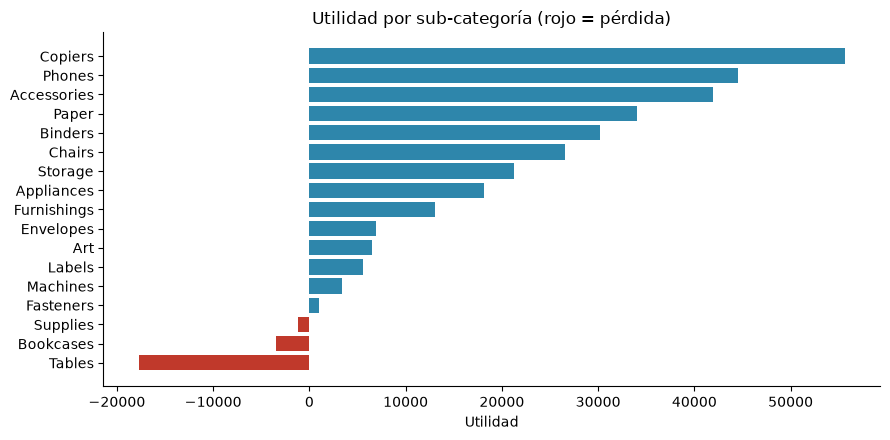

In [7]:
fig, ax = plt.subplots()
colores = ["#c0392b" if v < 0 else "#2e86ab" for v in por_sub["utilidad"]]
ax.barh(por_sub["sub_category"], por_sub["utilidad"], color=colores)
ax.set_title("Utilidad por sub-categoría (rojo = pérdida)")
ax.set_xlabel("Utilidad")
plt.tight_layout(); plt.savefig(FIG / "utilidad_subcategoria.png", dpi=150); plt.show()

In [11]:
por_sub.head(5)

,category,sub_category,ventas,utilidad,descuento_prom,margen_pct
3,Furniture,Tables,"206,965.53","-17,725.48",0.26,-8.56
0,Furniture,Bookcases,"114,880.00","-3,472.56",0.21,-3.02
12,Office Supplies,Supplies,"46,673.54","-1,189.10",0.08,-2.55
8,Office Supplies,Fasteners,"3,024.28",949.52,0.08,31.40
15,Technology,Machines,"189,238.63","3,384.76",0.31,1.79


## 4. ¿Los descuentos destruyen margen?

In [9]:
bins = [-0.001, 0, 0.1, 0.2, 0.3, 0.5, 1]
labels = ["0%", "0-10%", "10-20%", "20-30%", "30-50%", ">50%"]
df["tramo_desc"] = pd.cut(df["discount"], bins=bins, labels=labels)

desc = (df.groupby("tramo_desc", observed=True)
          .agg(ventas=("sales", "sum"), utilidad=("profit", "sum"), lineas=("sales", "size"))
          .assign(margen_pct=lambda t: t["utilidad"] / t["ventas"] * 100)
          .reset_index())
desc

,tramo_desc,ventas,utilidad,lineas,margen_pct
0,0%,"1,087,908.47","320,987.60",4798,29.51
1,0-10%,"54,369.35","9,029.18",94,16.61
2,10-20%,"792,152.89","91,756.30",3709,11.58
3,20-30%,"103,226.65","-10,369.28",227,-10.05
4,30-50%,"195,314.76","-48,447.73",310,-24.80
5,>50%,"64,228.74","-76,559.05",856,-119.20


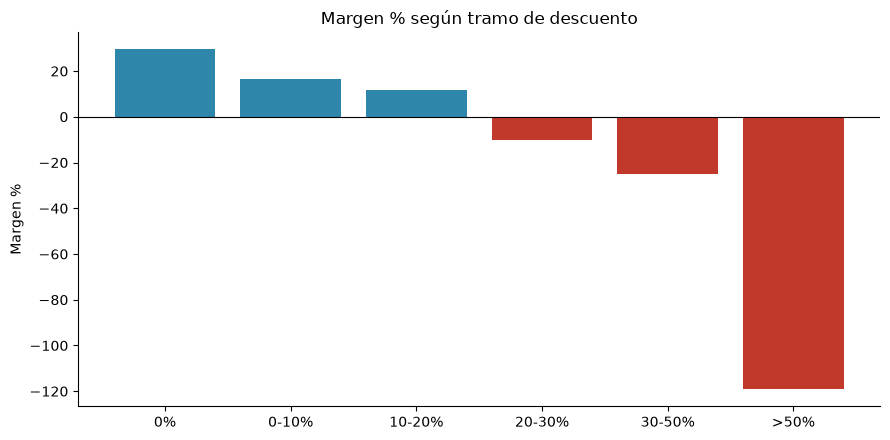

In [10]:
fig, ax = plt.subplots()
ax.bar(desc["tramo_desc"].astype(str), desc["margen_pct"],
       color=["#c0392b" if v < 0 else "#2e86ab" for v in desc["margen_pct"]])
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Margen % según tramo de descuento")
ax.set_ylabel("Margen %")
plt.tight_layout(); plt.savefig(FIG / "margen_vs_descuento.png", dpi=150); plt.show()

In [12]:
df[df["discount"] > 0.2].groupby("category").agg(lineas=("sales","size"), utilidad=("profit", "sum"))

,lineas,utilidad
category,,
Furniture,542,"-54,477.76"
Office Supplies,680,"-47,140.14"
Technology,171,"-33,758.16"


## 5. Productos y regiones con mayor pérdida

In [13]:
peores = (df.groupby("product_name")["profit"].sum().sort_values().head(10).reset_index())
region = resumen("region")
display(peores); display(region)

,product_name,profit
0,Cubify CubeX 3D Printer Double Head Print,"-8,879.97"
1,Lexmark MX611dhe Monochrome Laser Printer,"-4,589.97"
2,Cubify CubeX 3D Printer Triple Head Print,"-3,839.99"
3,Chromcraft Bull-Nose Wood Oval Conference Tabl...,"-2,876.12"
4,Bush Advantage Collection Racetrack Conference...,"-1,934.40"
5,GBC DocuBind P400 Electric Binding System,"-1,878.17"
6,Cisco TelePresence System EX90 Videoconferenci...,"-1,811.08"
7,Martin Yale Chadless Opener Electric Letter Op...,"-1,299.18"
8,Balt Solid Wood Round Tables,"-1,201.06"
9,BoxOffice By Design Rectangular and Half-Moon ...,"-1,148.44"


,region,ventas,utilidad,descuento_prom,margen_pct
0,Central,"501,239.89","39,706.36",0.24,7.92
2,South,"391,721.91","46,749.43",0.15,11.93
1,East,"678,781.24","91,522.78",0.15,13.48
3,West,"725,457.82","108,418.45",0.11,14.94


## 6. Tendencia mensual

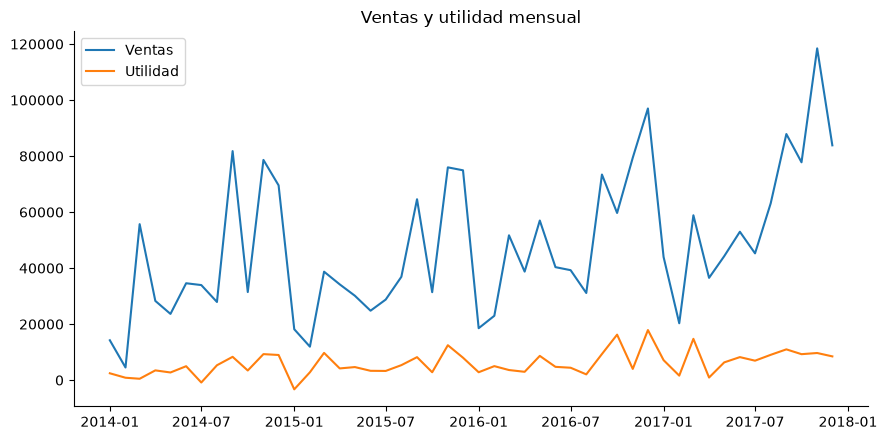

In [14]:
mensual = (df.set_index("order_date").resample("MS")
             .agg(ventas=("sales", "sum"), utilidad=("profit", "sum")))
mensual["margen_pct"] = mensual["utilidad"] / mensual["ventas"] * 100

fig, ax = plt.subplots()
ax.plot(mensual.index, mensual["ventas"], label="Ventas")
ax.plot(mensual.index, mensual["utilidad"], label="Utilidad")
ax.set_title("Ventas y utilidad mensual"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "tendencia_mensual.png", dpi=150); plt.show()

## 7. Exportar tablas para Power BI

In [15]:
df.to_csv(OUT / "ventas_limpio.csv", index=False)
por_sub.to_csv(OUT / "rentabilidad_subcategoria.csv", index=False)
desc.to_csv(OUT / "margen_por_descuento.csv", index=False)
mensual.reset_index().to_csv(OUT / "tendencia_mensual.csv", index=False)
print("Tablas exportadas en", OUT.resolve())

Tablas exportadas en C:\Users\KevinHP\Documents\proyectos\superstore-rentabilidad\reports


## ¿qué pasaría con un tope de descuento de 20 %?

In [16]:
TOPE = 0.20
alto = df[df["discount"] > TOPE].copy()

lista = alto["sales"] / (1 - alto["discount"])   # precio sin descuento
costo = alto["sales"] - alto["profit"]           # costo implícito de la línea
nueva_venta = lista * (1 - TOPE)                 # venta si el descuento se limita al tope
nueva_utilidad = nueva_venta - costo

base_alto = alto["profit"].sum()
utilidad_total = df["profit"].sum()

filas = []
for retencion in [1.0, 0.7, 0.5, 0.0]:          # % de esas ventas que se mantiene
    nueva = retencion * nueva_utilidad.sum()
    filas.append({"ventas_retenidas": f"{retencion:.0%}",
                  "mejora_utilidad": nueva - base_alto})
esc1 = pd.DataFrame(filas)
esc1["mejora_pct_utilidad_total"] = esc1["mejora_utilidad"] / utilidad_total * 100
esc1

,ventas_retenidas,mejora_utilidad,mejora_pct_utilidad_total
0,100%,"219,190.99",76.53
1,70%,"194,046.51",67.75
2,50%,"177,283.53",61.90
3,0%,"135,376.06",47.27


## Otras dos palancas, comparadas

In [18]:
neg_sub = por_sub[por_sub["utilidad"] < 0]
mejora_sub = -neg_sub["utilidad"].sum()          # llevar a cero las sub-categorías con pérdida
mejora_top10 = -peores["profit"].sum()           # llevar a cero los 10 peores productos

m = region.set_index("region")
mejora_central = m.loc["Central", "ventas"] * (m.loc["West", "margen_pct"] - m.loc["Central", "margen_pct"]) / 100

resumen_impacto = pd.DataFrame({
    "recomendacion": ["Revisar costo de sub-categorias con perdida",
                      "Renegociar los 10 productos mas perdedores",
                      "Alinear descuentos de Central con West"],
    "impacto_estimado": [mejora_sub, mejora_top10, mejora_central]})
resumen_impacto["pct_utilidad_actual"] = resumen_impacto["impacto_estimado"] / utilidad_total * 100
resumen_impacto

,recomendacion,impacto_estimado,pct_utilidad_actual
0,Revisar costo de sub-categorias con perdida,"22,387.14",7.82
1,Renegociar los 10 productos mas perdedores,"29,458.37",10.29
2,Alinear descuentos de Central con West,"35,203.09",12.29


## 8. Conclusiones y recomendaciones

### Hallazgos
1. **Furniture** aporta el 32 % de las ventas pero solo el 6 % de la utilidad (margen 2,5 % vs ~17 % en las otras categorías). Tables, Bookcases y Supplies operan con pérdida.
2. Con **descuentos superiores al 20 %** el margen se vuelve negativo (de -10 % a -119 %). Esas 1.393 líneas (14 % del total) generaron pérdidas por **USD 135 mil**, el 47 % de la utilidad total.
3. Las pérdidas por descuentos altos se reparten en las tres categorías (Furniture 40 %, Office Supplies 35 %, Technology 25 %): es un problema de política de descuentos, no solo de mezcla de productos.
4. La región **Central** opera con 24 % de descuento promedio y 7,9 % de margen, frente a 11 % y 14,9 % en West.
5. Los 10 productos más perdedores acumulan USD 29 mil de pérdida; 4 son mesas y 2 son impresoras 3D (USD 12,7 mil entre ambas).

### Recomendaciones e impacto estimado
| Prioridad | Recomendación | Impacto estimado en utilidad |
|---|---|---|
| 1 | Tope de descuento de 20 %, con aprobación gerencial sobre ese nivel | +USD 135 mil (+47 %) en el escenario más conservador; hasta +USD 219 mil (+77 %) si se mantienen todas las ventas |
| 2 | Alinear la política de descuentos de Central con la de West | ~USD 35 mil (+12 %) |
| 3 | Renegociar o discontinuar los 10 productos más perdedores | ~USD 29 mil (+10 %) |
| 4 | Revisar costo y precio de Tables, Bookcases y Supplies | ~USD 22 mil (+8 %) |

*Los impactos se solapan entre sí y no deben sumarse.*

### Supuestos y limitaciones
- La columna `Sales` ya incluye el descuento y el costo de cada línea no cambia con él.
- La simulación no modela la reacción de los clientes ni los costos fijos; el escenario conservador (perder todas esas ventas) no depende de la reacción de los clientes.
- Dataset de ejemplo (Tableau/Kaggle) con fines educativos, no datos de una empresa real.